<h1>Importation des libraries</h1>

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import tarfile
import os
import missingno as msno
import random
from sklearn.preprocessing import StandardScaler

<h1> Pipeline de pré-traitement </h1>

<h1> 1. Collecte des données </h1>

In [9]:
file_path = '../data/deux_fibre.csv'
data = pd.read_csv(file_path, sep=',')
data.head()

,ID,Tipo de fibra 1,Tipo de fibra 2,Dias curado,Dosage 1 (Kg/m3),Dosage 2 (Kg/m3),% Celulosa 1,% Celulosa 2,MEB 1,MEB 2,...,Etalement t=0 (mm),Teneur en air (%),Masse volumique (Kg/m3),Retrait,Coef.absorcion t=1 (%) Fibre 1,Coef.absorcion t=5 (%) Fibre 1,Coef.absorcion t=2880 (%) Fibre 1,Coef.absorcion t=1 (%) Fibre 2,Coef.absorcion t=5 (%) Fibre 2,Coef.absorcion t=2880 (%) Fibre 2
0,M1,CH5,B15,1.0,0.6,1.8,72,50,1,4,...,442.5,4.40,2.148,6.0,84.80,121.57,135.27,48.70,64.37,89.70
1,M2,CH5,M15,1.0,0.6,1.8,72,47,1,3,...,460.0,4.25,2.148,7.0,84.80,121.57,135.27,154.73,180.07,277.07
2,M3,L6,B15,1.0,0.6,1.8,71,50,2,4,...,437.5,4.00,2.15,4.0,21.30,34.23,155.27,48.70,64.37,89.70
3,M4,L6,M15,1.0,0.6,1.8,71,47,2,3,...,457.5,4.30,2.14,5.0,21.30,34.23,155.27,154.73,180.07,277.07
4,M5,CH.ANTIF. Antif,NO,1.0,0.6,0.0,Syntéthique,Syntéthique,Syntéthique,Syntéthique,...,395.0,NaN,NaN,1.0,Syntéthique,Syntéthique,Syntéthique,Syntéthique,Syntéthique,Syntéthique


In [10]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 197 entries, 0 to 196
Data columns (total 22 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   ID                                 196 non-null    str    
 1   Tipo de fibra 1                    196 non-null    str    
 2   Tipo de fibra 2                    196 non-null    str    
 3   Dias curado                        196 non-null    float64
 4   Dosage 1 (Kg/m3)                   196 non-null    float64
 5   Dosage 2 (Kg/m3)                   196 non-null    float64
 6   % Celulosa 1                       196 non-null    str    
 7   % Celulosa 2                       196 non-null    str    
 8   MEB 1                              196 non-null    str    
 9   MEB 2                              196 non-null    str    
 10  Rf (MPa)                           148 non-null    float64
 11  Rc (MPa)                           148 non-null    float64
 12  Etale

In [11]:
data.describe()

,Dias curado,Dosage 1 (Kg/m3),Dosage 2 (Kg/m3),Rf (MPa),Rc (MPa),Etalement t=0 (mm),Teneur en air (%),Retrait
count,196.000000,196.000000,196.000000,148.000000,148.000000,148.000000,140.000000,196.000000
mean,31.750000,0.734694,1.836735,6.010473,23.187432,453.162162,4.058571,4.000000
std,35.737989,0.356364,1.224484,1.788795,7.900655,22.767101,0.561663,2.005122
min,1.000000,0.000000,0.000000,1.510000,4.340000,395.000000,3.000000,1.000000
25%,5.500000,0.600000,0.000000,4.682500,15.425000,442.500000,4.000000,2.000000
50%,17.500000,0.800000,2.400000,6.430000,25.350000,452.500000,4.300000,4.000000
75%,43.750000,1.000000,2.800000,7.270000,29.070000,460.000000,4.400000,6.000000
max,91.000000,1.200000,3.200000,9.980000,35.210000,490.000000,4.800000,7.000000


<h1> 2. Nettoyage des données </h1>

<h2>2.1 Valeur manquantes</h2>

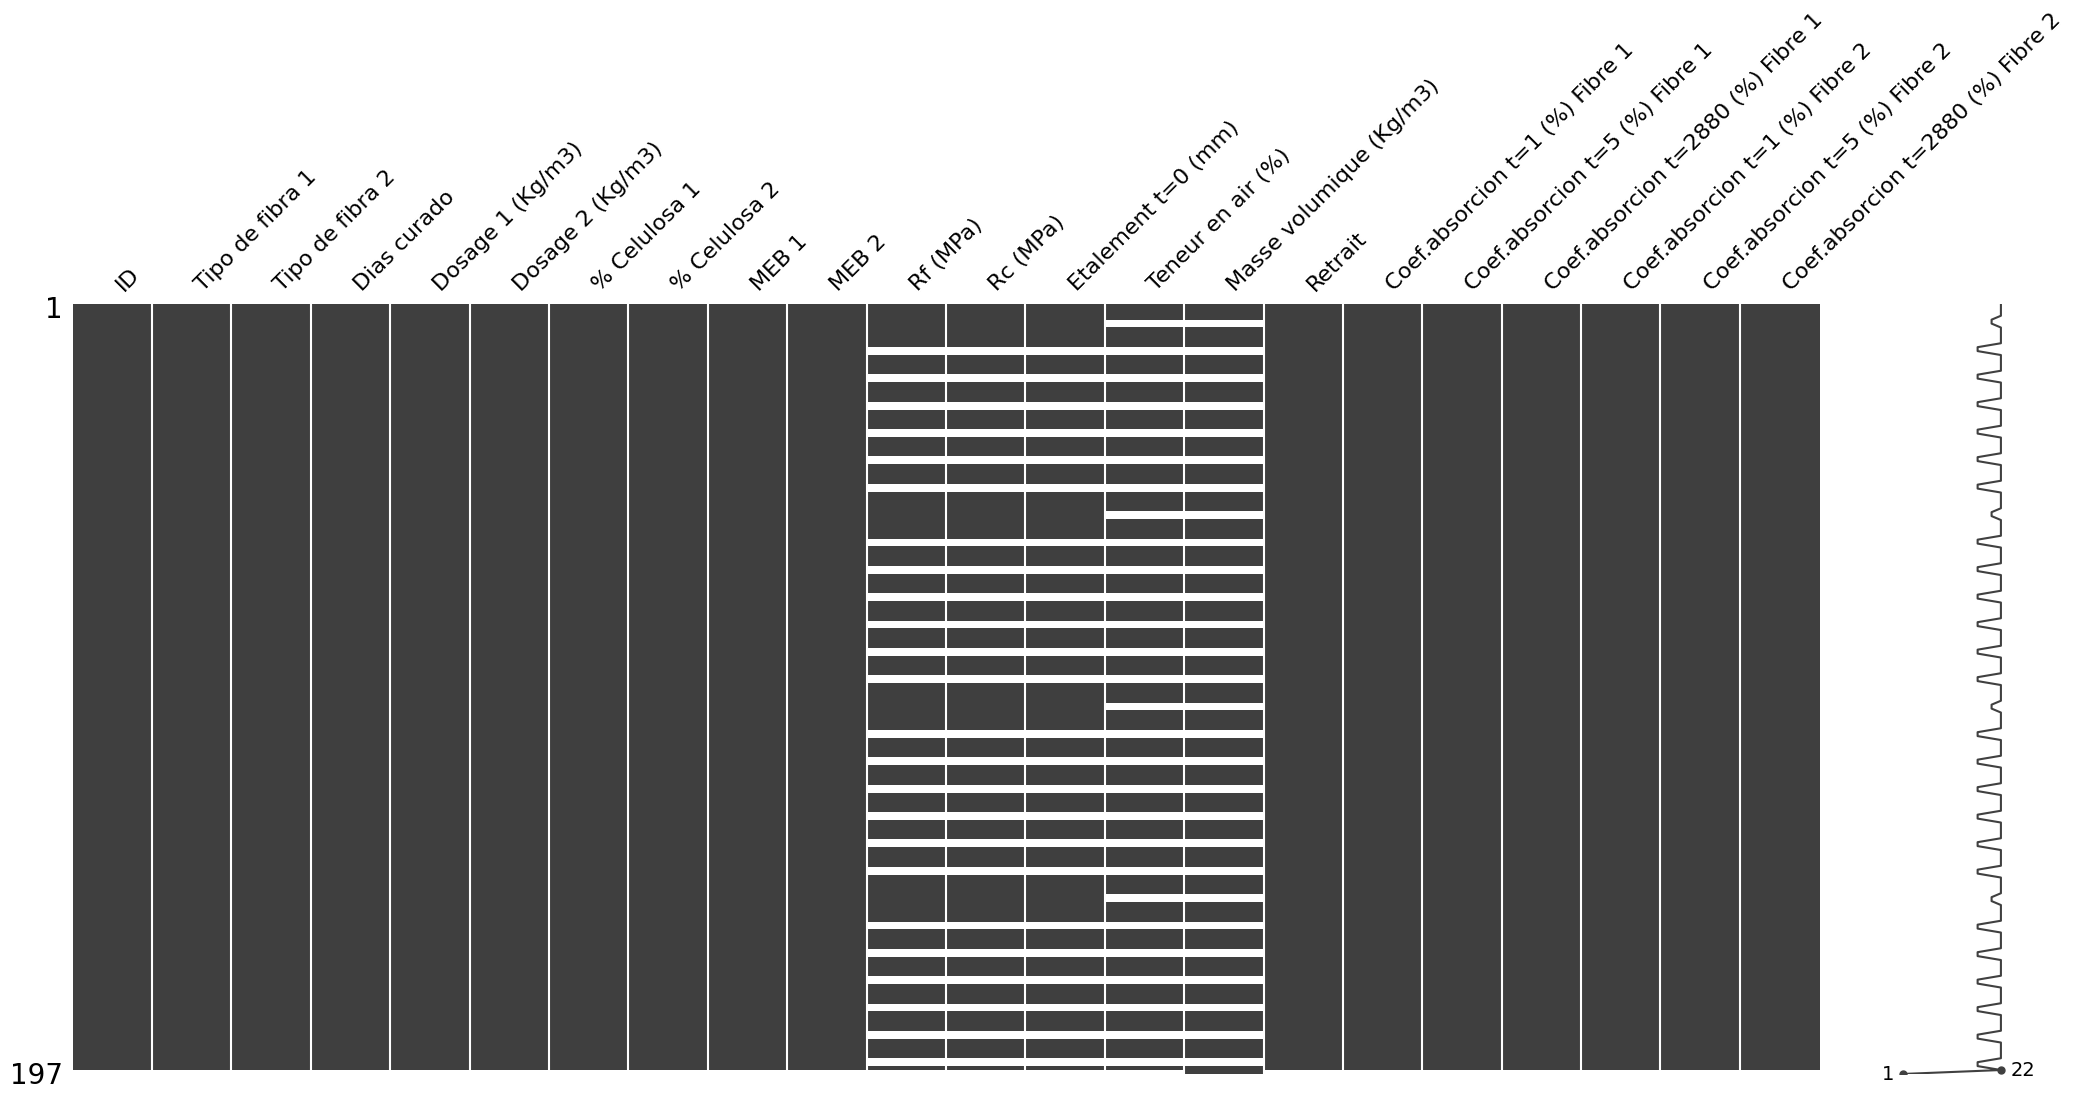

In [12]:
# Visualize missing data
msno.matrix(data)
plt.show()

In [13]:
def show_metric(data, column):
    print("=" * 50)
    print(f"{column:^50}")
    print("=" * 50)
    print(f"{'Données manquantes':<35} {data[column].isna().sum():>10}")
    print(f"{'% manquantes':<35} {round((data[column].isna().sum() / len(data)) * 100, 2):>9}%")
    print(f"{'Données disponibles':<35} {data[column].notna().sum():>10}")
    print(f"Lignes non alignées avec la colonne cible : {len([index for index, row in data.iterrows() if pd.isna(row[column]) and not pd.isna(row['Rc (MPa)'])])}")
    print("=" * 50)

show_metric(data, 'Rc (MPa)')

                     Rc (MPa)                     
Données manquantes                          49
% manquantes                            24.87%
Données disponibles                        148
Lignes non alignées avec la colonne cible : 0


<p style="color: grey;">
Le dataset présente <strong>49 valeurs manquantes</strong> pour la résistance à la compression (Rc), ce qui réduit le nombre de lignes exploitables à <strong>148 lignes valides</strong>. Cette contrainte influence directement le choix du modèle, car un réseau de neurones artificiel (ANN) nécessite généralement un volume de données plus important pour généraliser correctement. Nous nous orienterons donc vers des modèles reconnus pour leurs meilleures performances sur des datasets de taille réduite : <strong>Random Forest, XGBoost, SVR (Support Vector Regression)</strong> et <strong>Decision Tree</strong>.
</p>

In [14]:
show_metric(data, 'Rf (MPa)')
show_metric(data, 'Etalement t=0 (mm)')
show_metric(data, 'Teneur en air (%)')
show_metric(data, 'Masse volumique (Kg/m3)')

                     Rf (MPa)                     
Données manquantes                          49
% manquantes                            24.87%
Données disponibles                        148
Lignes non alignées avec la colonne cible : 0
                Etalement t=0 (mm)                
Données manquantes                          49
% manquantes                            24.87%
Données disponibles                        148
Lignes non alignées avec la colonne cible : 0
                Teneur en air (%)                 
Données manquantes                          57
% manquantes                            28.93%
Données disponibles                        140
Lignes non alignées avec la colonne cible : 8
             Masse volumique (Kg/m3)              
Données manquantes                          56
% manquantes                            28.43%
Données disponibles                        141
Lignes non alignées avec la colonne cible : 8


<p style="color: grey;">
Les données manquantes des colonnes ne correspondent pas toutes aux mêmes lignes que celles manquantes pour Rc (MPa). En effet, 8 lignes des colonnes <strong>Teneur en air</strong> et <strong>Masse volumique</strong> présentent des valeurs manquantes qui ne coïncident pas avec les lignes manquantes de la colonne cible. Ces valeurs manquantes résiduelles feront l'objet d'un traitement spécifique dans la partie suivante (imputation par médiane, moyenne, etc.). Ainsi, après suppression des 49 lignes sans valeur Rc, l'ensemble des colonnes restantes peut être conservé pour l'entraînement du modèle.
</p>

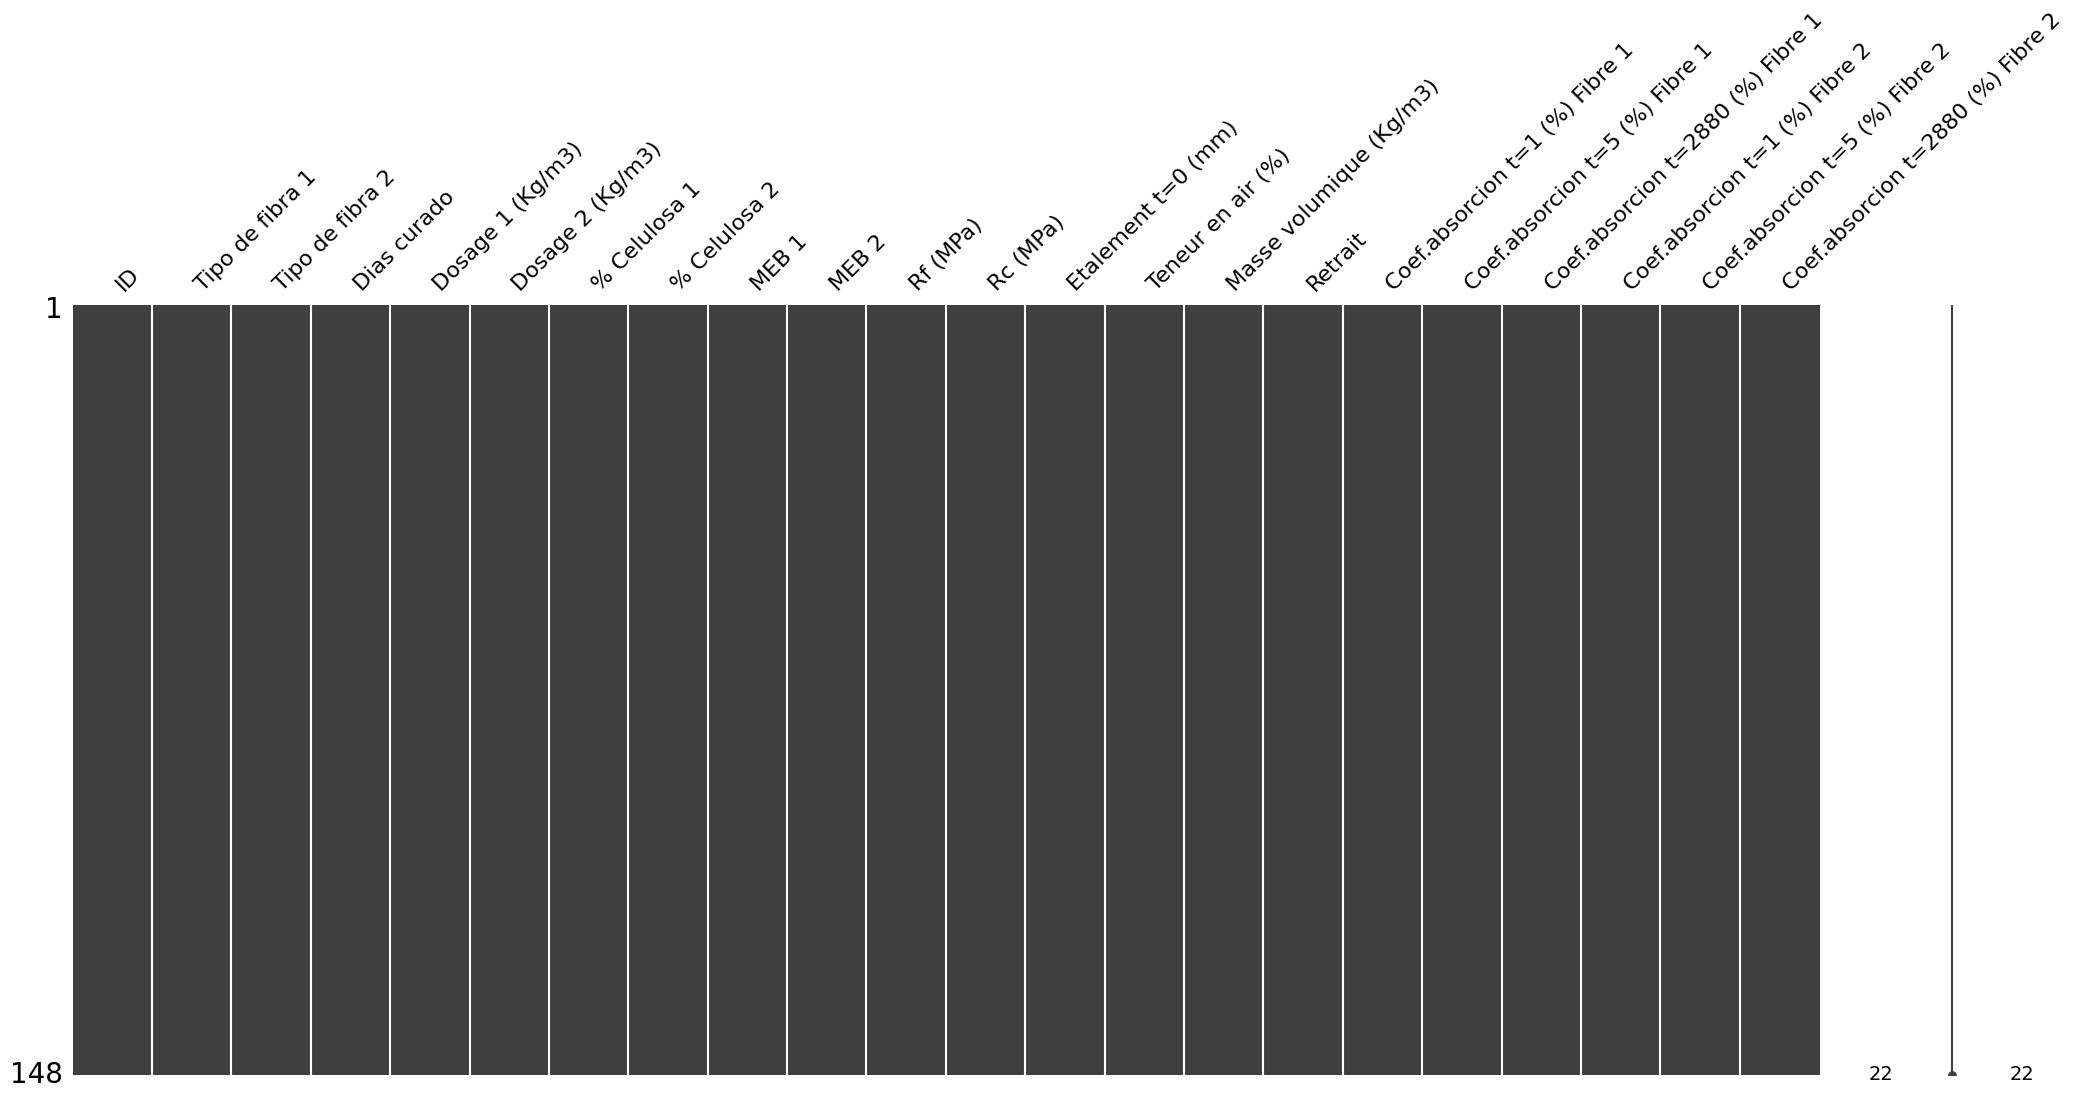

In [15]:
#suppression des lignes avec des valeurs manquantes dans la colonne cible
data = data.dropna(subset=['Rc (MPa)'])
#traitement des valeurs manquantes dans les autres colonnes
data['Masse volumique (Kg/m3)'] = pd.to_numeric(data['Masse volumique (Kg/m3)'], errors='coerce')
data['Masse volumique (Kg/m3)'] = data['Masse volumique (Kg/m3)'] .fillna(data['Masse volumique (Kg/m3)'].median())
data['Teneur en air (%)'] = data['Teneur en air (%)'].fillna(data['Teneur en air (%)'].median())
# Visualize missing data
msno.matrix(data)
plt.show()

<p style="color: grey;">
Après traitement des valeurs manquantes, le dataset ne contient plus aucune valeur nulle et est prêt à être utilisé pour l'entraînement du modèle : 
</p>

<h2>2.2 Valeurs Aberrantes</h2>

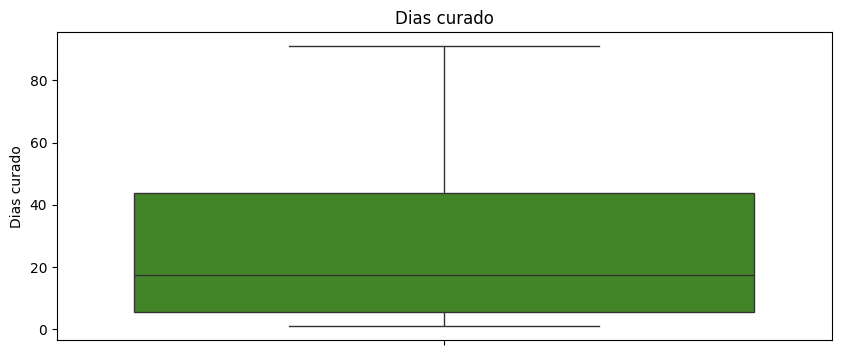

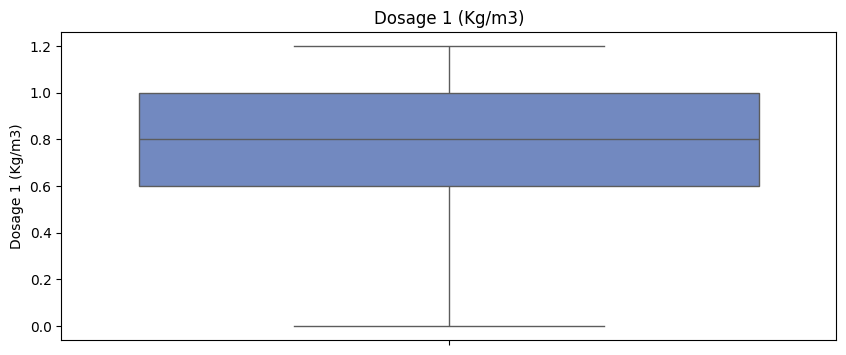

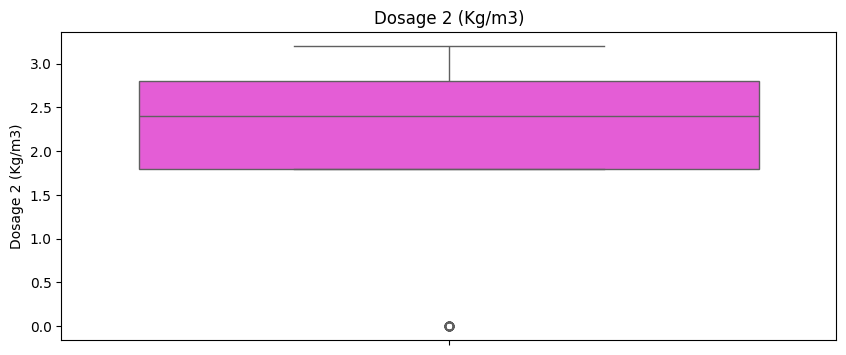

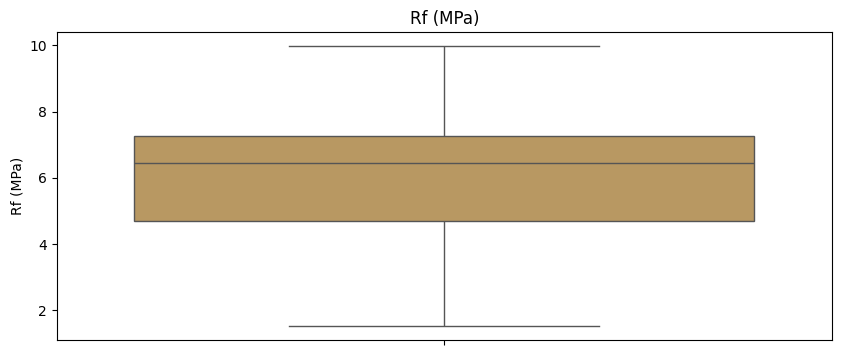

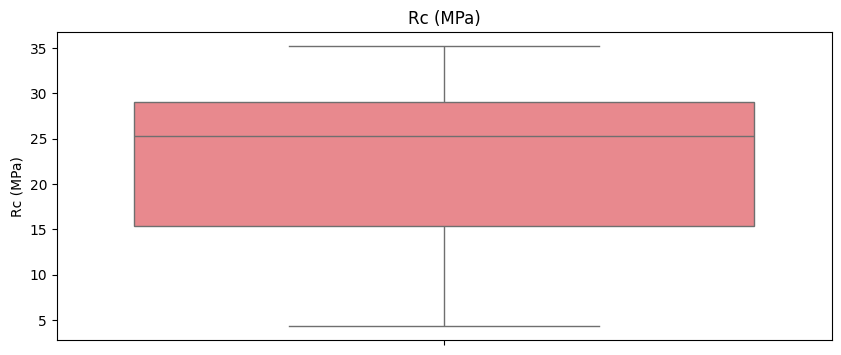

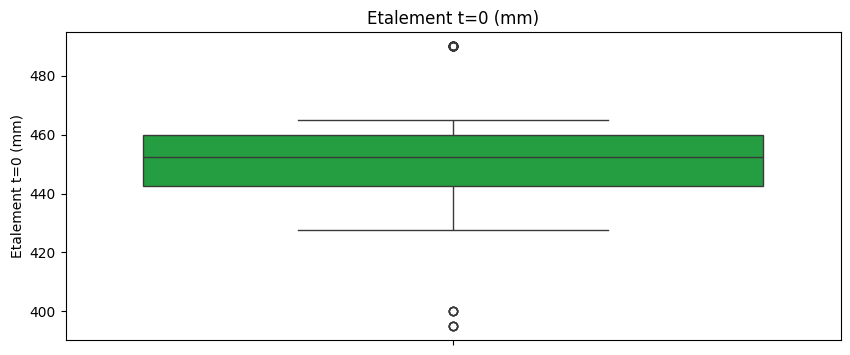

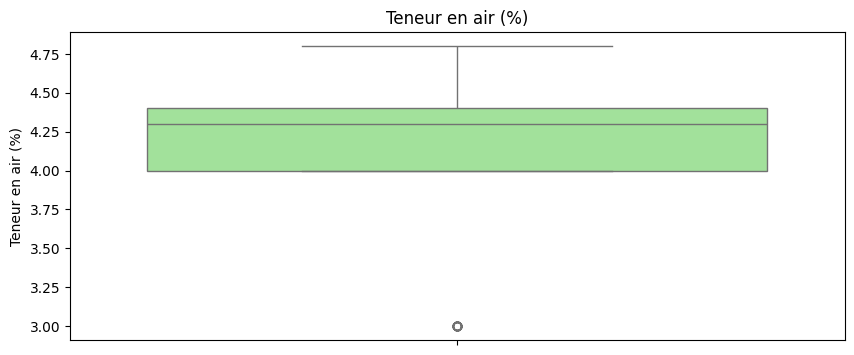

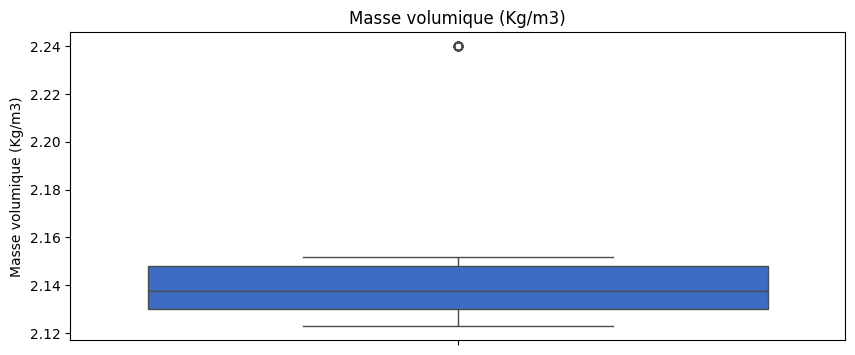

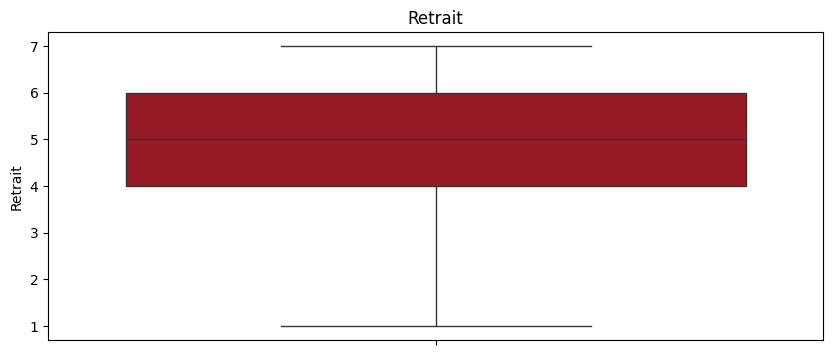

In [16]:
numerical_columns = data.select_dtypes(include=['float64', 'int64']).columns
for column in numerical_columns:
    plt.figure(figsize=(10, 4))
    sns.boxplot(y=data[column], color=tuple(np.random.rand(3)))
    plt.title(f'{column}')

    plt.show()

<p style="color: grey;">
On observe très peu de valeurs aberrantes dans le dataset. Dans notre contexte expérimental, ces valeurs ne résultent pas d'erreurs de mesure ou de saisie, mais reflètent des conditions réelles de formulation du mortier fibré. Elles constituent donc des informations précieuses pour l'entraînement du modèle, car elles permettent de couvrir une plus large plage de comportements mécaniques. Ces valeurs seront conservées telles quelles.
</p>

<h2>2.3 Sélection et cohérence des features</h2>

In [17]:
# corrélation entre rf(mpa) et rc(mpa)
data[['Rf (MPa)', 'Rc (MPa)']].corr()

,Rf (MPa),Rc (MPa)
Rf (MPa),1.00000,0.93889
Rc (MPa),0.93889,1.00000


<p style="color: grey;">
La colonne <strong>Rf (MPa)</strong> est supprimée afin d'éviter tout data leakage. En effet, la résistance à la flexion et la résistance à la compression sont mesurées simultanément lors du même test mécanique, ce qui en fait des variables fortement corrélées. Conserver Rf comme feature reviendrait à fournir au modèle une information qu'il ne pourrait pas avoir en conditions réelles, rendant la prédiction de Rc sans intérêt pratique.
</p>

In [18]:
data.drop('Rf (MPa)', axis=1, inplace=True)

<p style="color: grey;">
La colonne <strong>ID</strong> est également supprimée car elle ne représente qu'un identifiant technique sans aucune valeur prédictive pour le modèle.
</p>

In [19]:
data.drop('ID', axis=1, inplace=True)

<h1>3. Typage des données</h1>

In [ ]:
print(data.columns)

Index(['Tipo de fibra 1', 'Tipo de fibra 2', 'Dias curado', 'Dosage 1 (Kg/m3)',
       'Dosage 2 (Kg/m3)', '% Celulosa 1', '% Celulosa 2', 'MEB 1', 'MEB 2',
       'Rc (MPa)', 'Etalement t=0 (mm)', 'Teneur en air (%)',
       'Masse volumique (Kg/m3)', 'Retrait', 'Coef.absorcion t=1 (%) Fibre 1',
       'Coef.absorcion t=5 (%) Fibre 1', 'Coef.absorcion t=2880 (%) Fibre 1',
       'Coef.absorcion t=1 (%) Fibre 2', 'Coef.absorcion t=5 (%) Fibre 2',
       'Coef.absorcion t=2880 (%) Fibre 2'],
      dtype='str')


In [21]:
#export en csv 
data.to_csv('../data/cleaned_data.csv', index=False)